# Notebook 2 — Rectified Flow: enderezar trayectorias para muestrear en 1–2 pasos

**Aprendizaje Profundo · Presentación: Flow Matching & Rectified Flows**

En el Notebook 1 vimos que el flujo aprendido con CFM tiene **trayectorias curvas**, y por eso necesita muchos pasos de integración. Aquí estudiamos dos formas de **enderezarlas**:

1. **Reflow** [Liu, Gong & Liu, 2023 — *Flow Straight and Fast*]: reentrenar el flujo con los pares $(x_0, x_1)$ que *él mismo* genera.
2. **Minibatch OT-CFM** [Tong et al., 2023; Pooladian et al., 2023]: emparejar ruido y datos con **transporte óptimo** dentro de cada minibatch.

Y terminamos con **destilación a un paso**.

**Convención:** $t=0$ ruido, $t=1$ datos. Se ejecuta en CPU en ~2–3 minutos.

In [1]:
import math, time, copy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

SAVE_FIGS = True
FIG_DIR = "figuras"
import os; os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11})
C_NOISE, C_DATA, C_TRAJ = "#9aa5b1", "#d1495b", "#00798c"
COLORS = {"1-RF (CFM)": "#00798c", "2-RF (reflow)": "#d1495b", "OT-CFM": "#edae49", "2-RF + destilación": "#30638e"}

def savefig(name):
    if SAVE_FIGS: plt.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")

def style(ax, lim=4):
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])

device: cpu


## 0. Utilidades (las mismas que en el Notebook 1)

In [2]:
def sample_moons(n, noise=0.05):
    t = torch.rand(n) * math.pi
    upper = torch.rand(n) < 0.5
    x = torch.where(upper, torch.cos(t), 1 - torch.cos(t))
    y = torch.where(upper, torch.sin(t), 0.5 - torch.sin(t))
    return (torch.stack([x, y], 1) + noise * torch.randn(n, 2) - torch.tensor([0.5, 0.25])) * 2.0

def sample_8gaussians(n, r=3.0, std=0.15):
    ang = torch.randint(0, 8, (n,)) * (2 * math.pi / 8)
    return torch.stack([torch.cos(ang), torch.sin(ang)], 1) * r + std * torch.randn(n, 2)

class TimeEmbedding(nn.Module):
    def __init__(self, dim=32):
        super().__init__()
        self.register_buffer("freqs", torch.exp(torch.linspace(0, math.log(1000), dim // 2)))
    def forward(self, t):
        a = t[:, None] * self.freqs[None]
        return torch.cat([torch.sin(a), torch.cos(a)], dim=1)

class VelocityMLP(nn.Module):
    def __init__(self, dim=2, hidden=256, temb=32):
        super().__init__()
        self.temb = TimeEmbedding(temb)
        self.net = nn.Sequential(nn.Linear(dim + temb, hidden), nn.SiLU(),
                                 nn.Linear(hidden, hidden), nn.SiLU(),
                                 nn.Linear(hidden, hidden), nn.SiLU(),
                                 nn.Linear(hidden, dim))
    def forward(self, x, t):
        return self.net(torch.cat([x, self.temb(t)], dim=1))

@torch.no_grad()
def sample_ode(model, x0, steps=100, method="euler", return_traj=False):
    x, h = x0.clone().to(device), 1.0 / steps
    traj = [x.cpu()]
    for i in range(steps):
        t = torch.full((x.shape[0],), i * h, device=device)
        if method == "euler":
            x = x + h * model(x, t)
        else:  # punto medio
            x = x + h * model(x + 0.5 * h * model(x, t), t + 0.5 * h)
        if return_traj: traj.append(x.cpu())
    return (x.cpu(), torch.stack(traj)) if return_traj else x.cpu()

def sliced_wasserstein(a, b, n_proj=256, seed=0):
    gen = torch.Generator().manual_seed(seed)
    d = torch.randn(a.shape[1], n_proj, generator=gen); d = d / d.norm(dim=0, keepdim=True)
    pa, pb = torch.sort(a @ d, dim=0)[0], torch.sort(b @ d, dim=0)[0]
    return ((pa - pb) ** 2).mean().sqrt().item()

## 1. Entrenador genérico: lo único que cambia es **cómo se emparejan** $(x_0, x_1)$

La pérdida de Rectified Flow es la misma que la de CFM con camino lineal:
$$\min_\theta\ \mathbb E_{t,\,(x_0,x_1)\sim\pi}\ \big\|v_\theta(x_t,t) - (x_1-x_0)\big\|^2,\qquad x_t = (1-t)x_0 + t x_1 .$$
La diferencia entre métodos está en el **acoplamiento** $\pi(x_0, x_1)$:

| método | acoplamiento $\pi$ |
|---|---|
| 1-Rectified Flow (= CFM) | independiente: $x_0 \sim p_0$, $x_1 \sim q$ por separado |
| 2-Rectified Flow (*reflow*) | $x_1 = \text{ODE}_{\text{1-RF}}(x_0)$ — pares generados por el flujo anterior |
| OT-CFM | transporte óptimo dentro del minibatch |

In [3]:
def pair_independent(sample_p0, sample_q):
    def f(batch):
        return sample_p0(batch), sample_q(batch)
    return f

def pair_from_dataset(X0, X1):
    def f(batch):
        idx = torch.randint(0, X0.shape[0], (batch,))
        return X0[idx], X1[idx]
    return f

def pair_minibatch_ot(sample_p0, sample_q):
    def f(batch):
        x0, x1 = sample_p0(batch), sample_q(batch)
        C = torch.cdist(x0, x1) ** 2                       # coste cuadrático
        r, c = linear_sum_assignment(C.numpy())             # asignación óptima (Hungarian)
        return x0[r], x1[c]
    return f

def train_rf(pair_sampler, iters=5000, batch=512, lr=1e-3, init=None, seed=0, t_fixed=None):
    torch.manual_seed(seed)
    model = copy.deepcopy(init) if init is not None else VelocityMLP()
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, iters)
    for it in range(iters):
        x0, x1 = (z.to(device) for z in pair_sampler(batch))
        t = torch.rand(batch, device=device) if t_fixed is None else torch.full((batch,), t_fixed, device=device)
        xt = (1 - t[:, None]) * x0 + t[:, None] * x1
        loss = ((model(xt, t) - (x1 - x0)) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return model.eval()

@torch.no_grad()
def straightness(model, x0, steps=100):
    # S = ∫ E || (Z1 - Z0) - v(Z_t, t) ||^2 dt  (Liu et al., 2023). S = 0  <=>  trayectorias rectas
    x1, traj = sample_ode(model, x0, steps=steps, return_traj=True)
    disp = (traj[-1] - traj[0]).to(device)
    S = 0.0
    for i in range(steps):
        t = torch.full((x0.shape[0],), i / steps, device=device)
        S += ((disp - model(traj[i].to(device), t)) ** 2).sum(1).mean().item() / steps
    return S

## 2. Intuición: dos gaussianas → dos gaussianas

El ejemplo canónico del paper. Ruido: dos gaussianas a la izquierda. Datos: dos gaussianas a la derecha. Con acoplamiento independiente, la mitad de las rectas $x_0\to x_1$ son diagonales y **se cruzan** en el centro.

In [4]:
def two_blobs(x_center):
    def f(n, std=0.35):
        sign = torch.where(torch.rand(n) < 0.5, 1.0, -1.0)
        return torch.stack([torch.full((n,), x_center), 2.0 * sign], 1) + std * torch.randn(n, 2)
    return f
p0_toy, q_toy = two_blobs(-3.0), two_blobs(3.0)

t0 = time.time()
rf1_toy = train_rf(pair_independent(p0_toy, q_toy), iters=4000)
# reflow: generamos pares (z0, z1 = ODE_1RF(z0)) y reentrenamos (partiendo de los pesos de 1-RF)
Z0 = p0_toy(20000); Z1 = sample_ode(rf1_toy, Z0, steps=100, method="midpoint")
rf2_toy = train_rf(pair_from_dataset(Z0, Z1), iters=4000, init=rf1_toy, lr=5e-4)
print(f"{time.time()-t0:.1f}s")

26.7s


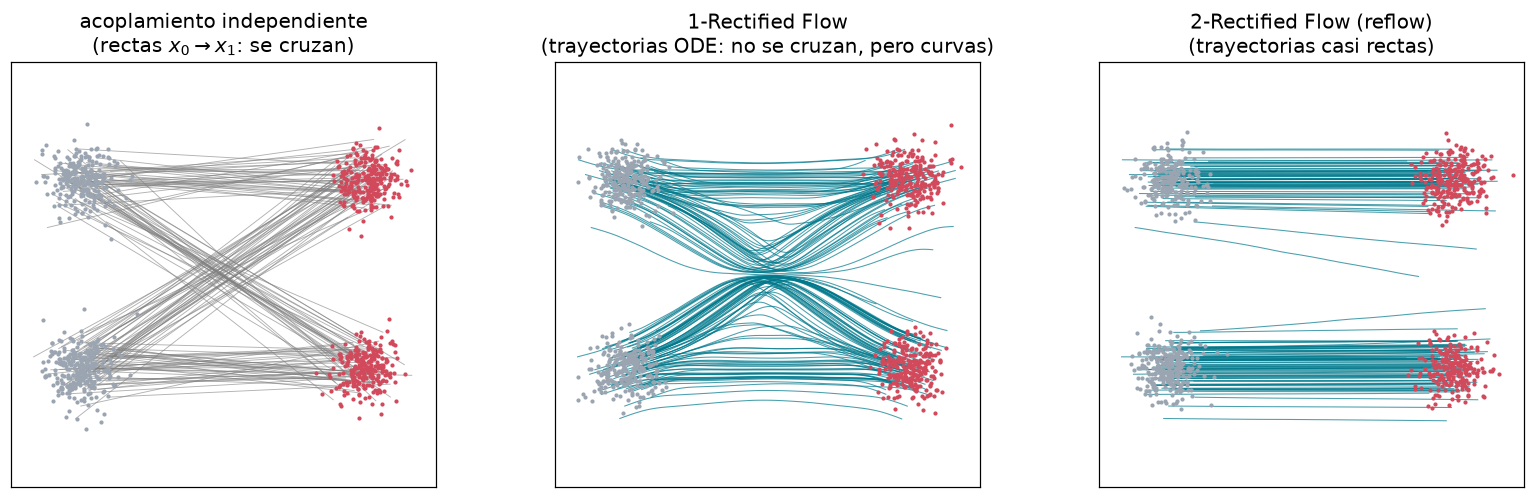

rectitud S: 1-RF = 5.2159 | 2-RF = 0.0002


In [5]:
z = p0_toy(250, std=0.35)
x1_ind = q_toy(250)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
ax = axs[0]
for i in range(150):
    ax.plot([z[i, 0], x1_ind[i, 0]], [z[i, 1], x1_ind[i, 1]], c="gray", lw=0.6, alpha=0.6)
ax.set_title("acoplamiento independiente\n(rectas $x_0 \\to x_1$: se cruzan)")
for ax, m, ttl in [(axs[1], rf1_toy, "1-Rectified Flow\n(trayectorias ODE: no se cruzan, pero curvas)"),
                   (axs[2], rf2_toy, "2-Rectified Flow (reflow)\n(trayectorias casi rectas)")]:
    _, tr = sample_ode(m, z, steps=100, return_traj=True)
    for i in range(150):
        ax.plot(tr[:, i, 0], tr[:, i, 1], c=C_TRAJ, lw=0.7, alpha=0.7)
    ax.set_title(ttl)
for ax in axs:
    ax.scatter(*p0_toy(500).T, s=3, c=C_NOISE, zorder=3); ax.scatter(*q_toy(500).T, s=3, c=C_DATA, zorder=3)
    style(ax, 4.5)
plt.tight_layout(); savefig("nb2_toy_reflow"); plt.show()
print("rectitud S: 1-RF =", round(straightness(rf1_toy, p0_toy(2000)), 4),
      "| 2-RF =", round(straightness(rf2_toy, p0_toy(2000)), 4))

**Qué está pasando:**
- **1-RF**: en el centro, la red aprende el *promedio* de velocidades. El flujo resultante **"desenreda" los cruces**: los puntos de arriba van arriba y los de abajo, abajo. Es decir, el flujo **reacopla** ruido y datos de forma determinista y sin cruces… pero sus trayectorias son curvas.
- **2-RF**: si ahora entrenamos con esos nuevos pares (que ya no se cruzan), las rectas condicionales **coinciden** con las trayectorias, el promedio no deforma nada y el flujo se vuelve **recto**.

Propiedades (Liu et al., 2023):
1. Cada *reflow* **conserva las marginales** ($p_0$ y $q$ siguen siendo las mismas).
2. **No aumenta el coste de transporte** $\mathbb E\,c(x_1-x_0)$ para *cualquier* coste convexo $c$.
3. La rectitud mejora: un flujo perfectamente recto se integra **exactamente con un solo paso de Euler**.

## 3. Caso realista: ruido gaussiano → datos

Ahora comparamos los tres acoplamientos con $p_0=\mathcal N(0,I)$ y unos datos 2D, midiendo calidad frente a NFE.

In [6]:
sample_q = sample_8gaussians          # <- prueba también sample_moons
sample_p0 = lambda n: torch.randn(n, 2)

models, times = {}, {}
t0 = time.time(); models["1-RF (CFM)"] = train_rf(pair_independent(sample_p0, sample_q), iters=6000); times["1-RF (CFM)"] = time.time() - t0

# Reflow (2-RF): pares generados por 1-RF con un integrador preciso
t0 = time.time()
Z0 = sample_p0(50000)
Z1 = sample_ode(models["1-RF (CFM)"], Z0, steps=100, method="midpoint")
models["2-RF (reflow)"] = train_rf(pair_from_dataset(Z0, Z1), iters=6000, init=models["1-RF (CFM)"], lr=5e-4)
times["2-RF (reflow)"] = time.time() - t0

t0 = time.time(); models["OT-CFM"] = train_rf(pair_minibatch_ot(sample_p0, sample_q), iters=6000, batch=256); times["OT-CFM"] = time.time() - t0

# Destilación a un paso: aprender x1 ≈ z0 + v(z0, 0) con los pares del 2-RF
t0 = time.time()
W0 = sample_p0(50000)
W1 = sample_ode(models["2-RF (reflow)"], W0, steps=100, method="midpoint")
models["2-RF + destilación"] = train_rf(pair_from_dataset(W0, W1), iters=4000, init=models["2-RF (reflow)"], lr=5e-4, t_fixed=0.0)
times["2-RF + destilación"] = time.time() - t0

for k, v in times.items(): print(f"{k:22s} {v:6.1f}s")

1-RF (CFM)               15.7s
2-RF (reflow)            24.9s
OT-CFM                   54.7s
2-RF + destilación       19.2s


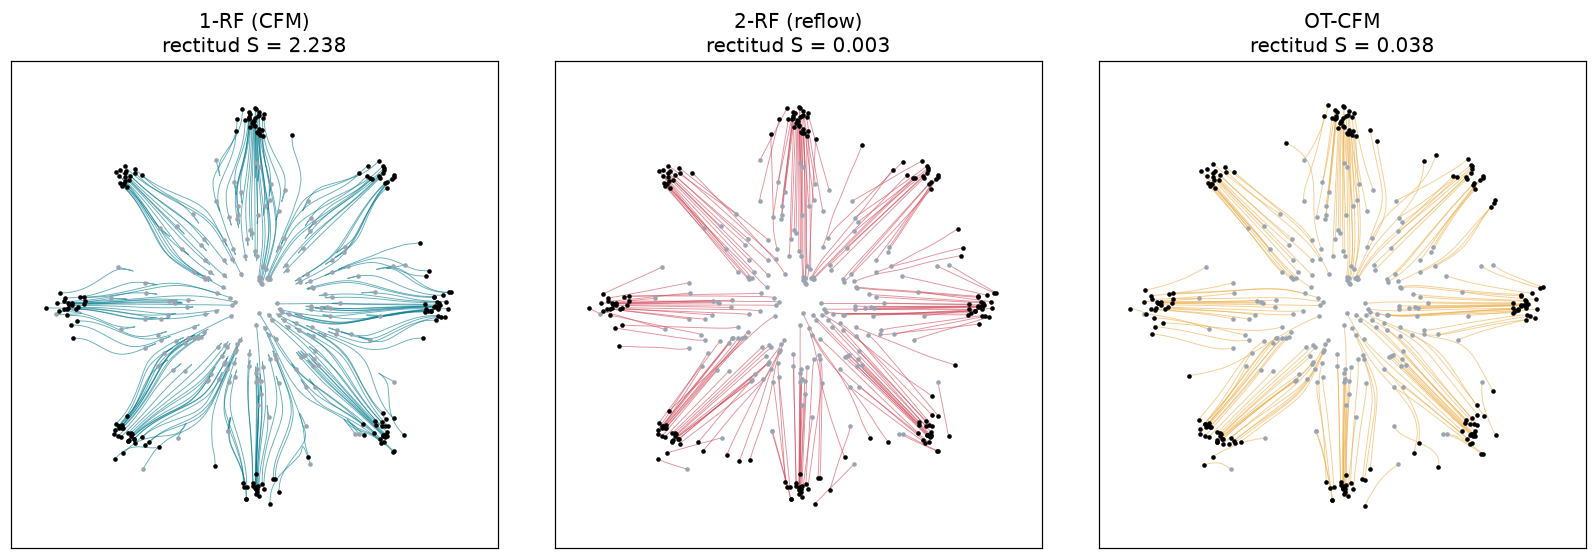

In [7]:
z_traj = sample_p0(200)
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, name in zip(axs, ["1-RF (CFM)", "2-RF (reflow)", "OT-CFM"]):
    _, tr = sample_ode(models[name], z_traj, steps=100, return_traj=True)
    for i in range(200):
        ax.plot(tr[:, i, 0], tr[:, i, 1], c=COLORS[name], lw=0.6, alpha=0.6)
    ax.scatter(*tr[0].T, s=4, c=C_NOISE, zorder=3); ax.scatter(*tr[-1].T, s=4, c="k", zorder=3)
    S = straightness(models[name], sample_p0(3000))
    ax.set_title(f"{name}\nrectitud S = {S:.3f}"); style(ax, 4)
plt.tight_layout(); savefig("nb2_trajectories"); plt.show()

### Calidad frente a NFE — el resultado principal

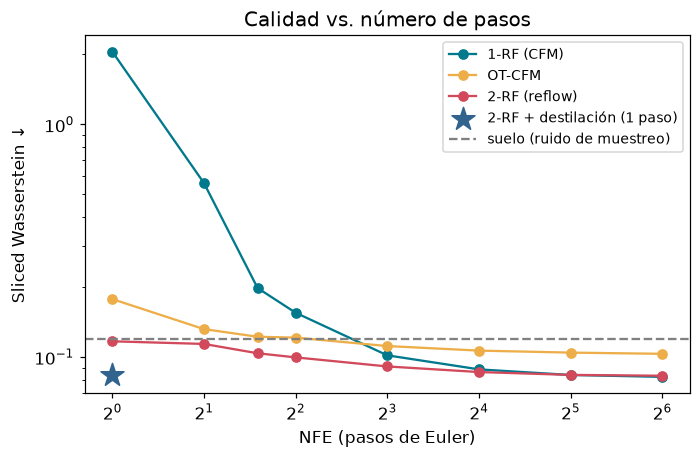

 NFE      1-RF (CFM)          OT-CFM   2-RF (reflow)
   1          2.0537          0.1774          0.1168
   2          0.5595          0.1318          0.1138
   3          0.1980          0.1222          0.1038
   4          0.1550          0.1212          0.0997
   8          0.1017          0.1115          0.0911
  16          0.0885          0.1066          0.0862
  32          0.0837          0.1045          0.0838
  64          0.0822          0.1032          0.0831
2-RF + destilación, 1 paso: 0.0839


In [8]:
N = 5000
z = sample_p0(N); ref = sample_q(N); floor = sliced_wasserstein(sample_q(N), ref)
nfes = [1, 2, 3, 4, 8, 16, 32, 64]
curves = {}
for name in ["1-RF (CFM)", "OT-CFM", "2-RF (reflow)"]:
    curves[name] = [sliced_wasserstein(sample_ode(models[name], z, steps=k), ref) for k in nfes]
distill_1step = sliced_wasserstein(sample_ode(models["2-RF + destilación"], z, steps=1), ref)

plt.figure(figsize=(6.5, 4.3))
for name, c in curves.items():
    plt.plot(nfes, c, "o-", c=COLORS[name], label=name)
plt.scatter([1], [distill_1step], marker="*", s=250, c=COLORS["2-RF + destilación"], zorder=5, label="2-RF + destilación (1 paso)")
plt.axhline(floor, ls="--", c="gray", label="suelo (ruido de muestreo)")
plt.xscale("log", base=2); plt.yscale("log")
plt.xlabel("NFE (pasos de Euler)"); plt.ylabel("Sliced Wasserstein ↓")
plt.title("Calidad vs. número de pasos"); plt.legend(fontsize=9)
plt.tight_layout(); savefig("nb2_nfe_curves"); plt.show()

print(f"{'NFE':>4} " + " ".join(f"{n:>15s}" for n in curves))
for i, k in enumerate(nfes):
    print(f"{k:>4} " + " ".join(f"{curves[n][i]:>15.4f}" for n in curves))
print("2-RF + destilación, 1 paso:", round(distill_1step, 4))

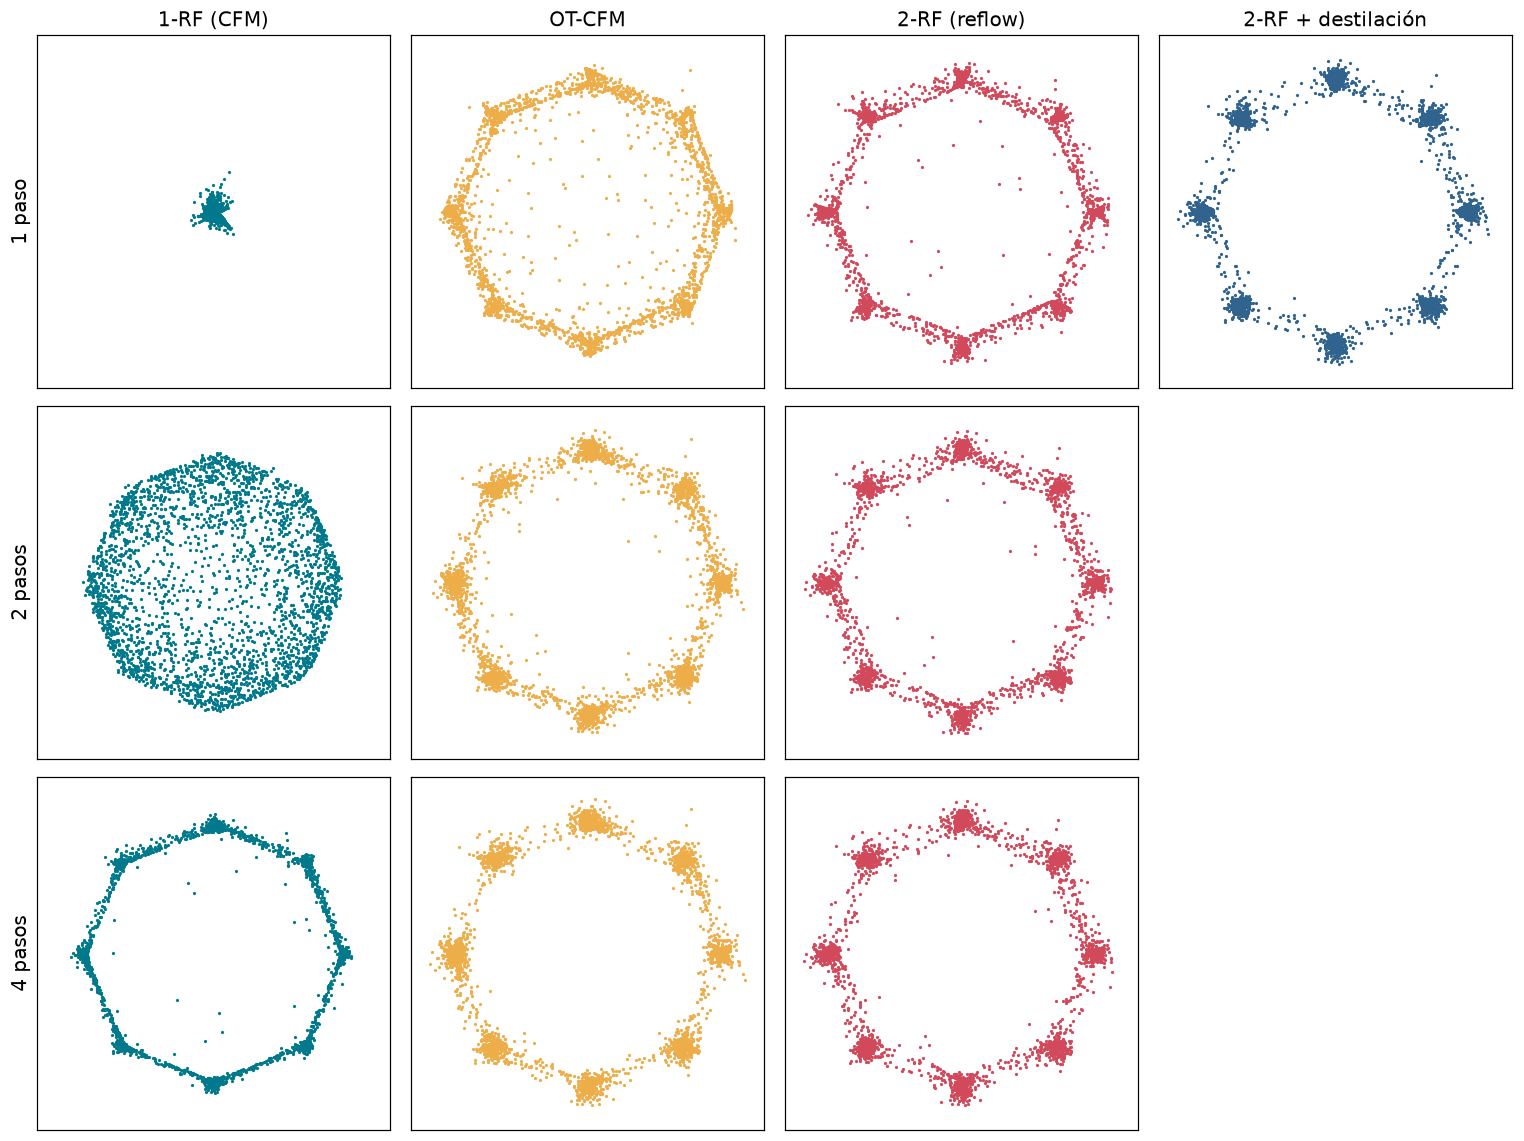

In [9]:
names = ["1-RF (CFM)", "OT-CFM", "2-RF (reflow)", "2-RF + destilación"]
steps_list = [1, 2, 4]
fig, axs = plt.subplots(len(steps_list), len(names), figsize=(14, 10.5))
zz = z[:3000]
for j, name in enumerate(names):
    for i, k in enumerate(steps_list):
        ax = axs[i, j]
        if name == "2-RF + destilación" and k > 1:
            ax.axis("off"); continue
        ax.scatter(*sample_ode(models[name], zz, steps=k).T, s=1.2, c=COLORS[name])
        style(ax, 4)
        if i == 0: ax.set_title(name)
        if j == 0: ax.set_ylabel(f"{k} paso{'s' if k > 1 else ''}", fontsize=13)
plt.tight_layout(); savefig("nb2_few_step_grid"); plt.show()

**Lectura de los resultados**
- Con **1 paso**, 1-RF colapsa hacia la media; 2-RF y OT-CFM ya reproducen los 8 modos.
- 2-RF con 2 pasos es tan bueno como 1-RF con ~8; la versión destilada iguala con **1 paso** a 1-RF con ~32.
- Con muchos pasos todos convergen… salvo **OT-CFM, que se estanca algo por encima**. Una explicación plausible: el emparejamiento OT del minibatch divide el espacio de ruido en regiones que van a modos distintos, con fronteras **bruscas**, y la red (suave) no puede reproducirlas, de modo que deja masa entre modos. Además, el OT del minibatch sólo aproxima el OT global. (Probamos con `batch=512` y no mejoró, así que no es sólo ruido de estimación.)

## 4. Discusión

| | 1-RF / CFM | OT-CFM | Reflow (2-RF) | + destilación |
|---|---|---|---|---|
| coste de entrenamiento | 1× | 1× + OT por minibatch | 1× + **generar pares** (simular la ODE) + reentrenar | + otro reentrenamiento |
| trayectorias | curvas | más rectas | casi rectas | — (mapa directo) |
| pasos para buena calidad | muchos | menos | **1–4** | **1** |
| riesgos | — | OT en minibatch ≠ OT global en alta dimensión | errores del 1-RF se heredan en los pares | pérdida de diversidad/detalle |

**En modelos reales:**
- **InstaFlow** (Liu et al., ICLR 2024) aplica reflow + destilación a Stable Diffusion: generación texto→imagen en **un paso**.
- **Stable Diffusion 3** (Esser et al., ICML 2024) usa el objetivo de Rectified Flow (camino lineal) **sin reflow**, con muestreo de $t$ logit-normal, y ve que escala mejor que las formulaciones clásicas de difusión.
- Alternativas modernas para 1 paso: *consistency models*, *shortcut models*, *MeanFlow* (aprende la velocidad **media** en un intervalo).

## 5. Ejercicios propuestos

1. **3-RF.** Aplica reflow una segunda vez. ¿Mejora la rectitud? ¿Y la calidad con 1 paso? (Pista: los errores se acumulan.)
2. **Precisión de los pares.** Genera los pares de reflow con sólo 10 pasos de Euler en lugar de 100 de punto medio. ¿Qué ocurre?
3. **Tamaño del minibatch en OT-CFM.** Prueba `batch=32` y `batch=1024`. ¿Cómo cambian la rectitud y el tiempo?
4. **Coste de transporte.** Calcula $\mathbb E\,\|x_1-x_0\|^2$ para los pares de cada método y comprueba que reflow no lo aumenta.